# EDA Practice Notebook: Missing Values, Outliers & Feature Engineering

This notebook is a hands-on, module-based guide to core Exploratory Data Analysis (EDA) skills. It is not tied to any single assignment or dataset. Each module below can be studied on its own, and a small practice dataset is generated at the start so every cell runs end to end without needing any external file.

**Modules covered:**
1. Initial Data Exploration
2. Missing Value Analysis and Handling
3. Outlier Detection and Treatment
4. Correlation Analysis
5. Feature Engineering

To use this notebook with your own data, replace the dataset generated in Module 0 with `pd.read_csv('your_file.csv')` and the rest of the notebook will work the same way, as long as your column names are adjusted where noted.

## Module 0: Setup and Practice Dataset

The dataset below is generated on the spot so this notebook is fully self-contained. It represents a generic retail/customer style dataset with the same kind of issues you will meet in real data: missing values, outliers, skewed columns, and a mix of numerical and categorical fields.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

rng = np.random.default_rng(7)
n = 400

df = pd.DataFrame({
    'CustomerID': [f'C{str(i).zfill(4)}' for i in range(1, n + 1)],
    'Age': np.clip(rng.normal(38, 12, n), 18, 80).round(),
    'AnnualIncome': np.clip(rng.normal(55000, 18000, n), 15000, None).round(2),
    'YearsAsCustomer': np.clip(rng.exponential(3, n), 0, 25).round(1),
    'MonthlySpend': np.clip(rng.gamma(2, 60, n), 5, None).round(2),
    'VisitsPerMonth': rng.integers(0, 20, n),
    'SatisfactionScore': rng.integers(1, 11, n),
    'Region': rng.choice(['North', 'South', 'East', 'West'], n, p=[0.3, 0.25, 0.25, 0.2]),
    'MembershipTier': rng.choice(['Bronze', 'Silver', 'Gold', 'Platinum'], n, p=[0.4, 0.3, 0.2, 0.1]),
    'Churned': rng.choice(['Yes', 'No'], n, p=[0.22, 0.78]),
})

# Inject a handful of extreme outliers
out_idx = rng.choice(n, 6, replace=False)
df.loc[out_idx, 'AnnualIncome'] = df.loc[out_idx, 'AnnualIncome'] * rng.uniform(3, 5, 6)
df.loc[rng.choice(n, 3, replace=False), 'Age'] = [95, 99, 5]
df.loc[rng.choice(n, 5, replace=False), 'MonthlySpend'] = rng.uniform(1500, 3000, 5)

# Inject missing values with different patterns
def inject_missing(col, frac, idx_pool=None):
    pool = df.index if idx_pool is None else idx_pool
    chosen = rng.choice(pool, int(len(pool) * frac), replace=False)
    df.loc[chosen, col] = np.nan

inject_missing('AnnualIncome', 0.05)
inject_missing('MembershipTier', 0.07)
inject_missing('YearsAsCustomer', 0.03)
low_satisfaction_idx = df.index[df['SatisfactionScore'] <= 3]
inject_missing('MonthlySpend', 0.3, idx_pool=low_satisfaction_idx)

print('Practice dataset created:', df.shape)
df.head()

Practice dataset created: (400, 10)


,CustomerID,Age,AnnualIncome,YearsAsCustomer,MonthlySpend,VisitsPerMonth,SatisfactionScore,Region,MembershipTier,Churned
0,C0001,38.0,58156.03,2.4,154.66,13,1,West,Silver,No
1,C0002,42.0,62057.71,2.6,84.96,17,6,West,NaN,No
2,C0003,35.0,48212.66,NaN,23.08,5,5,South,Silver,No
3,C0004,27.0,73525.23,0.7,24.24,4,2,South,Bronze,Yes
4,C0005,33.0,58787.11,0.2,239.01,0,9,North,Gold,No


## Module 1: Initial Data Exploration

Before doing anything else, get a clear picture of the dataset: its size, its column types, and any early warning signs.

In [2]:
print('Shape:', df.shape)
df.info()

Shape: (400, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         400 non-null    object 
 1   Age                400 non-null    float64
 2   AnnualIncome       380 non-null    float64
 3   YearsAsCustomer    388 non-null    float64
 4   MonthlySpend       364 non-null    float64
 5   VisitsPerMonth     400 non-null    int64  
 6   SatisfactionScore  400 non-null    int64  
 7   Region             400 non-null    object 
 8   MembershipTier     372 non-null    object 
 9   Churned            400 non-null    object 
dtypes: float64(4), int64(2), object(4)
memory usage: 31.4+ KB


**What to look for:** the `Non-Null Count` column in the output above tells you immediately which columns have missing data, just by comparing each count to the total number of rows.

In [3]:
display(df.describe())
display(df.describe(include='object'))

,Age,AnnualIncome,YearsAsCustomer,MonthlySpend,VisitsPerMonth,SatisfactionScore
count,400.000000,380.000000,388.000000,364.000000,400.000000,400.000000
mean,37.222500,54955.142654,2.946649,142.931791,9.352500,5.680000
std,11.502337,25661.051917,2.874078,228.623327,5.775086,2.917856
min,5.000000,15000.000000,0.000000,5.000000,0.000000,1.000000
25%,30.000000,41572.690000,0.800000,50.850000,4.000000,3.000000
50%,37.000000,53399.385000,2.100000,99.010000,9.000000,6.000000
75%,44.250000,64818.730000,4.125000,169.835000,14.000000,8.000000
max,99.000000,368752.938485,16.500000,2401.039512,19.000000,10.000000


,CustomerID,Region,MembershipTier,Churned
count,400,400,372,400
unique,400,4,4,2
top,C0384,North,Bronze,No
freq,1,115,149,314


**What to look for:** compare the mean, minimum, and maximum for each numerical column.
- If the maximum is far above the 75th percentile, or the minimum is far below the 25th percentile, that column likely has outliers.
- For categorical columns, `describe(include='object')` shows the most frequent category (`top`) and how often it appears (`freq`), which is a quick way to spot imbalance.

In [4]:
print('Duplicate rows:', df.duplicated().sum())

for col in ['Region', 'MembershipTier', 'Churned']:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

Duplicate rows: 0
--- Region ---
Region
North    115
East     100
South     94
West      91
Name: count, dtype: int64

--- MembershipTier ---
MembershipTier
Bronze      149
Silver      112
Gold         77
Platinum     34
NaN          28
Name: count, dtype: int64

--- Churned ---
Churned
No     314
Yes     86
Name: count, dtype: int64



**Observation:** `Churned` is imbalanced, with far fewer customers leaving than staying. This is common in real business data and matters later if you are building a predictive model, since a model can look accurate while simply predicting the majority class every time.

## Module 2: Missing Value Analysis and Handling

### 2.1 Why values go missing

Understanding why data is missing helps you choose the right fix. There are three commonly used categories:

- **MCAR (Missing Completely at Random):** the chance of a value being missing has nothing to do with any other data. A random system glitch is a typical cause.
- **MAR (Missing at Random):** the chance of being missing depends on another *observed* column. In this dataset, `MonthlySpend` is deliberately made more likely to be missing for customers with a low `SatisfactionScore`, which is exactly this pattern.
- **MNAR (Missing Not at Random):** the chance of being missing depends on the *missing value itself*. Income fields are a classic example, since very high or very low earners may be less willing to disclose their income.

You usually cannot prove which category applies with full certainty from the data alone. State your reasoning and treat it as a working assumption.

In [5]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({'MissingCount': missing_count, 'MissingPercent': missing_percent})
missing_summary = missing_summary[missing_summary['MissingCount'] > 0].sort_values('MissingPercent', ascending=False)
display(missing_summary)

,MissingCount,MissingPercent
MonthlySpend,36,9.0
MembershipTier,28,7.0
AnnualIncome,20,5.0
YearsAsCustomer,12,3.0


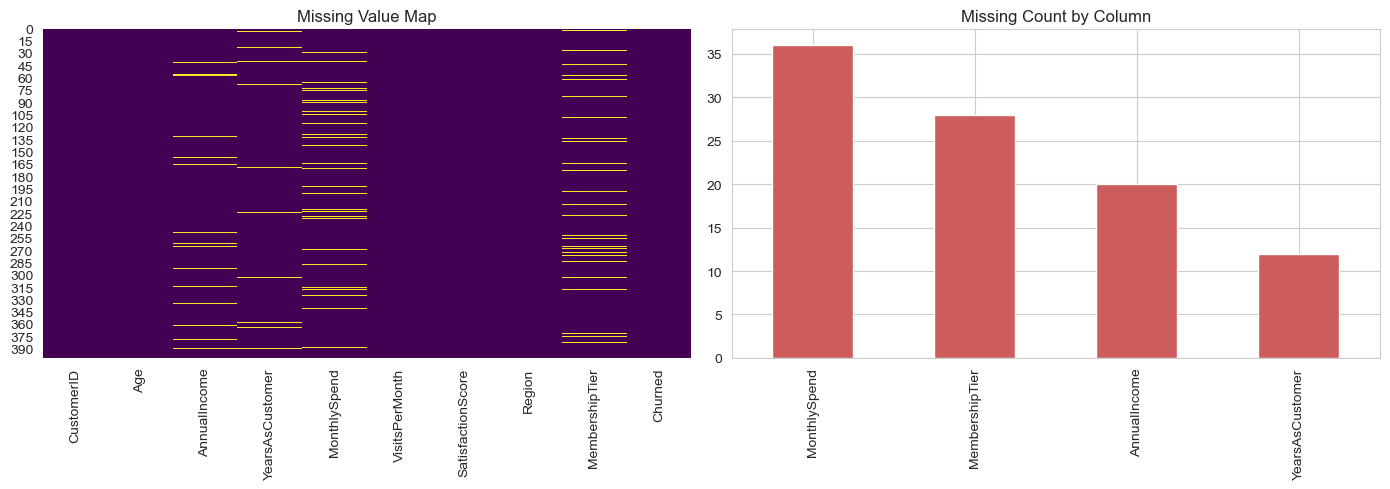

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Value Map')
missing_summary['MissingCount'].plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('Missing Count by Column')
plt.tight_layout()
plt.show()

**Tip:** the `missingno` package (`import missingno as msno`) gives you the same kind of view with less setup: `msno.matrix(df)` for the pattern, and `msno.heatmap(df)` to see whether missingness in one column tends to occur alongside missingness in another.

### 2.2 Handling techniques

Different columns usually need different treatment. Below are the four most common techniques, each applied to a different column in this dataset for comparison.

In [7]:
# Technique 1: Deletion — used when missingness is small and the column has little
# relationship to the rest of the data.
before_rows = len(df)
df = df.dropna(subset=['YearsAsCustomer']).reset_index(drop=True)
print(f'Rows dropped for YearsAsCustomer: {before_rows - len(df)}')

# Technique 2: Median imputation — used for a skewed numerical column, since the median
# is not pulled toward extreme values the way the mean is.
income_median = df['AnnualIncome'].median()
df['AnnualIncome'] = df['AnnualIncome'].fillna(income_median)
print('AnnualIncome imputed with median:', round(income_median, 2))

# Technique 3: Mode imputation — the standard choice for a categorical column with no
# strong relationship to other columns.
tier_mode = df['MembershipTier'].mode()[0]
df['MembershipTier'] = df['MembershipTier'].fillna(tier_mode)
print('MembershipTier imputed with mode:', tier_mode)

# Technique 4: Group-wise imputation — used because MonthlySpend's missingness pattern is
# related to SatisfactionScore, so filling within each satisfaction group is more accurate
# than a single global median.
df['MonthlySpend'] = df.groupby('SatisfactionScore')['MonthlySpend'].transform(lambda s: s.fillna(s.median()))
df['MonthlySpend'] = df['MonthlySpend'].fillna(df['MonthlySpend'].median())
print('MonthlySpend imputed group-wise by SatisfactionScore.')

print('\nRemaining missing values:', df.isnull().sum().sum())

Rows dropped for YearsAsCustomer: 12
AnnualIncome imputed with median: 53399.38
MembershipTier imputed with mode: Bronze
MonthlySpend imputed group-wise by SatisfactionScore.

Remaining missing values: 0


**A more advanced option: KNN imputation.** Instead of filling a value with a single statistic, `KNNImputer` looks at the most similar rows (nearest neighbors) based on other columns and fills the missing value using their average. This is useful when several numerical columns are related to each other.

```python
from sklearn.impute import KNNImputer

knn_imputer = KNNImputer(n_neighbors=5)
numeric_cols = ['Age', 'AnnualIncome', 'YearsAsCustomer', 'MonthlySpend']
df[numeric_cols] = knn_imputer.fit_transform(df[numeric_cols])
```

**Checking your work:** always compare the mean and standard deviation of a column before and after imputation. A large shift usually means the imputation method has distorted the original distribution, and a different technique may be a better fit.

## Module 3: Outlier Detection and Treatment

### 3.1 Visualizing outliers first

Box plots and histograms are the fastest way to see whether a column has outliers and whether it is skewed.

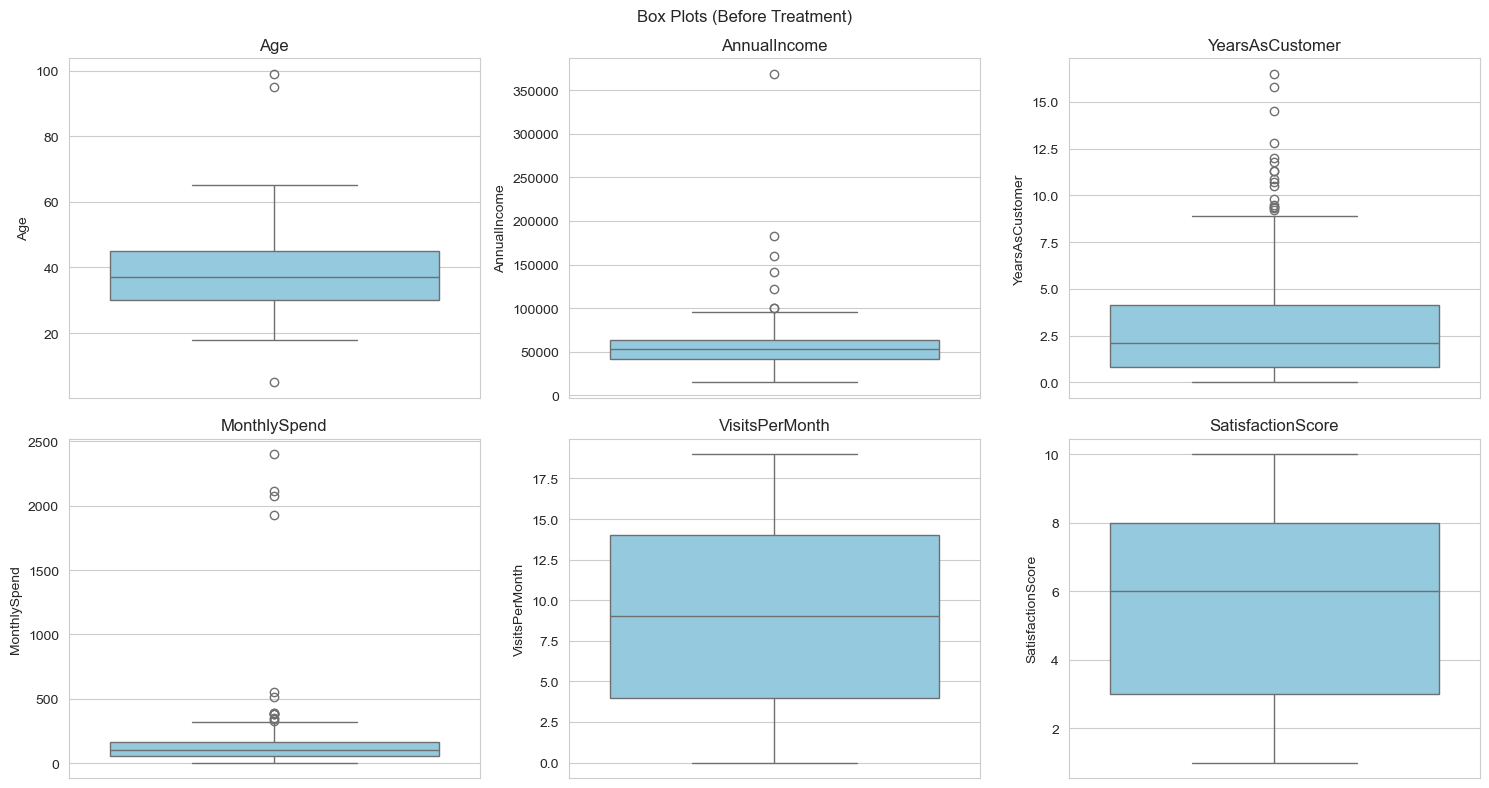

In [8]:
num_cols = ['Age', 'AnnualIncome', 'YearsAsCustomer', 'MonthlySpend', 'VisitsPerMonth', 'SatisfactionScore']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.suptitle('Box Plots (Before Treatment)')
plt.tight_layout()
plt.show()

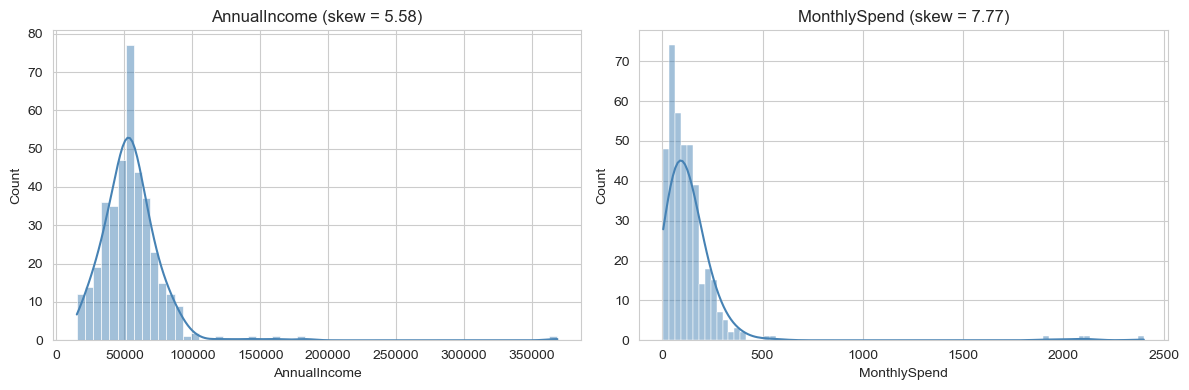

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['AnnualIncome'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title(f"AnnualIncome (skew = {df['AnnualIncome'].skew():.2f})")
sns.histplot(df['MonthlySpend'], kde=True, ax=axes[1], color='steelblue')
axes[1].set_title(f"MonthlySpend (skew = {df['MonthlySpend'].skew():.2f})")
plt.tight_layout()
plt.show()

**Observation:** `AnnualIncome` and `MonthlySpend` are both right-skewed, meaning most values sit toward the lower end with a long tail of high values. This is common for money-related columns and is a signal that the mean will be pulled upward, so median-based methods tend to describe these columns more fairly.

### 3.2 Detecting outliers: IQR vs Z-score

**IQR (Interquartile Range) method:** based on quartiles, so it is not distorted by extreme values. Good for skewed data.

**Z-score method:** based on the mean and standard deviation, so it assumes a roughly normal distribution. A common threshold is 3 standard deviations from the mean.

In [10]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

results = []
for col in ['Age', 'AnnualIncome', 'MonthlySpend']:
    lower, upper = iqr_bounds(df[col])
    n_iqr = ((df[col] < lower) | (df[col] > upper)).sum()
    n_z = (np.abs(stats.zscore(df[col])) > 3).sum()
    results.append({'Column': col, 'LowerBound': round(lower, 2), 'UpperBound': round(upper, 2),
                     'Outliers_IQR': n_iqr, 'Outliers_Zscore': n_z})

display(pd.DataFrame(results))

,Column,LowerBound,UpperBound,Outliers_IQR,Outliers_Zscore
0,Age,7.50,67.50,3,2
1,AnnualIncome,8813.54,97275.85,7,4
2,MonthlySpend,-106.88,327.29,14,4


**Observation:** the IQR method usually flags more outliers than the Z-score method on skewed columns like `AnnualIncome`, because a handful of extreme values inflate the standard deviation used by the Z-score calculation, which raises the bar for what counts as extreme. This is a good reason to check both methods rather than relying on just one.

**Multivariate option: Isolation Forest.** Some outliers are only visible when you look at several columns together, not one at a time. `IsolationForest` from scikit-learn is built for this.

```python
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.03, random_state=0)
df['is_outlier'] = iso.fit_predict(df[['Age', 'AnnualIncome', 'MonthlySpend']])
# -1 marks an outlier, 1 marks a normal point
```

### 3.3 Treating outliers

The right treatment depends on whether the value is a genuine (if rare) case, or clearly invalid.

Rows removed for invalid Age: 3
AnnualIncome capped to [8808.23, 97078.07]


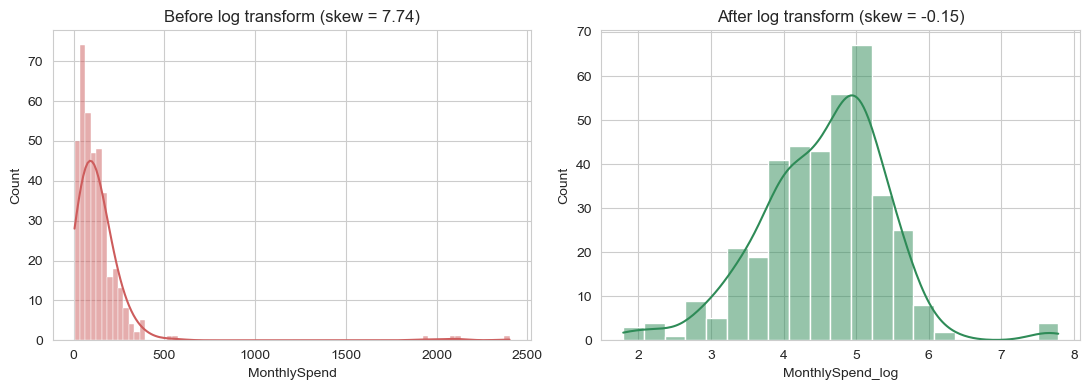

In [11]:
# Removal — used for Age, since a handful of values are outside any realistic working-age range
# and are best treated as data entry errors.
before_rows = len(df)
df = df[(df['Age'] >= 18) & (df['Age'] <= 85)].reset_index(drop=True)
print(f'Rows removed for invalid Age: {before_rows - len(df)}')

# Capping / winsorization — used for AnnualIncome, since very high incomes can be genuine
# and dropping them would lose real information. Capping limits their influence instead.
lower, upper = iqr_bounds(df['AnnualIncome'])
df['AnnualIncome_capped'] = df['AnnualIncome'].clip(lower=lower, upper=upper)
print(f'AnnualIncome capped to [{lower:.2f}, {upper:.2f}]')

# Transformation — used for MonthlySpend, to reduce right-skew while keeping every record.
df['MonthlySpend_log'] = np.log1p(df['MonthlySpend'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['MonthlySpend'], kde=True, ax=axes[0], color='indianred')
axes[0].set_title(f"Before log transform (skew = {df['MonthlySpend'].skew():.2f})")
sns.histplot(df['MonthlySpend_log'], kde=True, ax=axes[1], color='seagreen')
axes[1].set_title(f"After log transform (skew = {df['MonthlySpend_log'].skew():.2f})")
plt.tight_layout()
plt.show()

**Observation:** after the log transform, `MonthlySpend` looks noticeably closer to a symmetric, bell-shaped distribution, which is exactly the goal of a skew-reducing transformation. No data points were discarded to achieve this, unlike the removal strategy used for `Age`.

## Module 4: Correlation Analysis

Correlation measures how strongly two numerical columns move together. Three common methods:

| Method | Measures | Sensitive to outliers? | Best for |
|---|---|---|---|
| Pearson | Linear relationship | Yes | Roughly normal, unskewed data |
| Spearman | Monotonic relationship (based on ranks) | No | Skewed data or non-linear but consistent trends |
| Kendall | Monotonic relationship (pairwise agreement) | No | Smaller datasets, more conservative than Spearman |

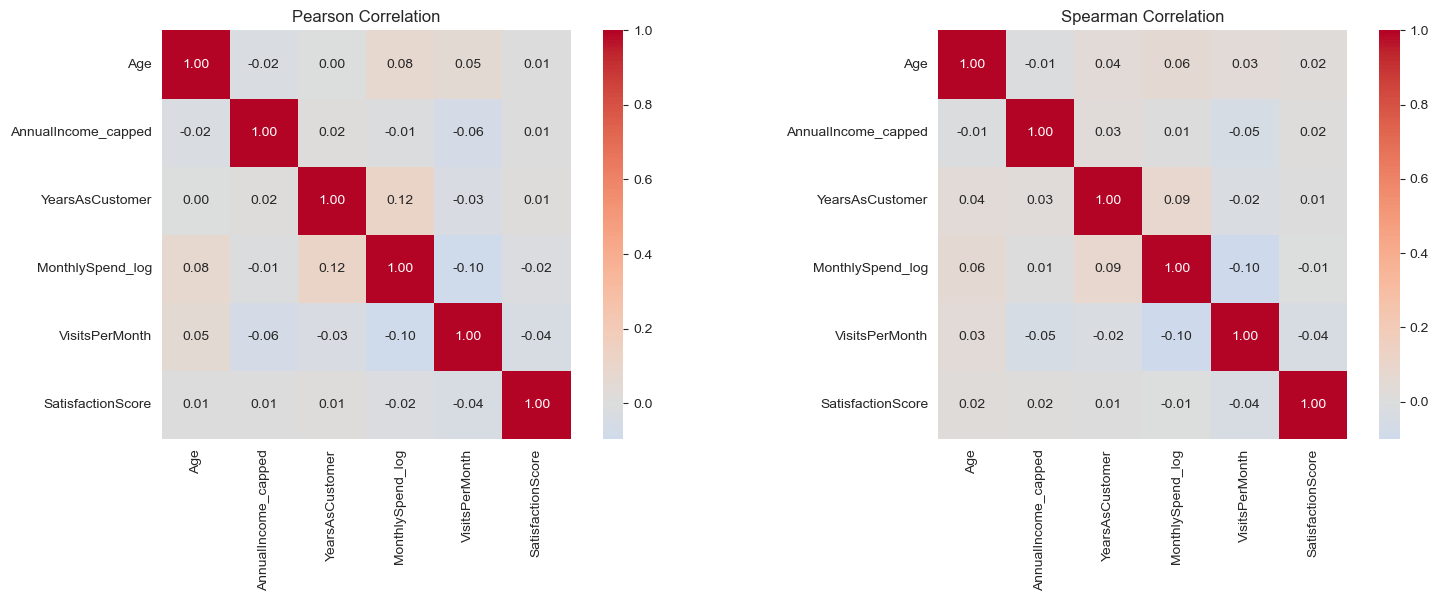

In [12]:
corr_cols = ['Age', 'AnnualIncome_capped', 'YearsAsCustomer', 'MonthlySpend_log', 'VisitsPerMonth', 'SatisfactionScore']

pearson_corr = df[corr_cols].corr(method='pearson')
spearman_corr = df[corr_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0], square=True)
axes[0].set_title('Pearson Correlation')
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1], square=True)
axes[1].set_title('Spearman Correlation')
plt.tight_layout()
plt.show()

**Observation:** where Pearson and Spearman disagree noticeably on a pair of columns, it is often a sign of outliers or a non-linear relationship between them. It is good practice to check both, especially on columns you know are skewed, such as income or spending data.

In [13]:
# Correlation with a target column, useful when preparing for a predictive model
df['Churned_encoded'] = df['Churned'].map({'No': 0, 'Yes': 1})
target_corr = df[corr_cols + ['Churned_encoded']].corr()['Churned_encoded'].drop('Churned_encoded')
display(target_corr.sort_values(key=abs, ascending=False).to_frame('CorrelationWithChurn'))

,CorrelationWithChurn
SatisfactionScore,-0.071328
VisitsPerMonth,-0.049216
MonthlySpend_log,-0.047901
Age,0.022312
AnnualIncome_capped,-0.019400
YearsAsCustomer,0.001604


**What to look for:** columns with a higher absolute correlation to the target are generally more promising candidate predictors, though correlation alone does not guarantee predictive value, especially for non-linear relationships that Pearson may understate.

## Module 5: Feature Engineering

Feature engineering means creating new columns that make patterns in the data easier for a model, or a person, to work with.

### 5.1 Binning: turning a continuous column into categories

In [14]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 30, 45, 60, 100],
                         labels=['18-30', '31-45', '46-60', '61+'])
display(df['AgeGroup'].value_counts().sort_index().to_frame('Count'))

,Count
AgeGroup,
18-30,105
31-45,191
46-60,82
61+,7


### 5.2 Ratio / derived features: combining columns to capture a relationship

In [15]:
df['SpendPerVisit'] = df['MonthlySpend'] / (df['VisitsPerMonth'] + 1)
df[['MonthlySpend', 'VisitsPerMonth', 'SpendPerVisit']].head()

,MonthlySpend,VisitsPerMonth,SpendPerVisit
0,154.66,13,11.047143
1,84.96,17,4.720000
2,24.24,4,4.848000
3,239.01,0,239.010000
4,22.42,8,2.491111


**Why this helps:** `SpendPerVisit` captures something neither original column does on its own. A customer with high total spend but very few visits behaves very differently from one who visits often but spends little each time, even if their `MonthlySpend` values look similar.

### 5.3 Binary flags: marking whether a value crosses a meaningful threshold

In [16]:
threshold = df['VisitsPerMonth'].quantile(0.75)
df['IsFrequentVisitor'] = (df['VisitsPerMonth'] > threshold).astype(int)
print(f'Threshold (75th percentile): {threshold:.1f} visits')
print(df['IsFrequentVisitor'].value_counts())

Threshold (75th percentile): 14.0 visits
IsFrequentVisitor
0    297
1     88
Name: count, dtype: int64


### 5.4 Encoding categorical variables

- **One-Hot Encoding** for nominal categories with no natural order, such as `Region`.
- **Ordinal / Label Encoding** for categories with a clear order, such as `MembershipTier`.

In [17]:
region_ohe = pd.get_dummies(df['Region'], prefix='Region')

tier_order = {'Bronze': 0, 'Silver': 1, 'Gold': 2, 'Platinum': 3}
df['MembershipTier_encoded'] = df['MembershipTier'].map(tier_order)

display(pd.concat([df[['Region']], region_ohe], axis=1).head())
display(df[['MembershipTier', 'MembershipTier_encoded']].head())

,Region,Region_East,Region_North,Region_South,Region_West
0,West,False,False,False,True
1,West,False,False,False,True
2,South,False,False,True,False
3,North,False,True,False,False
4,East,True,False,False,False


,MembershipTier,MembershipTier_encoded
0,Silver,1
1,Bronze,0
2,Bronze,0
3,Gold,2
4,Bronze,0


**Why the choice matters:** encoding `Region` ordinally would falsely imply that one region is 'greater' than another. Encoding `MembershipTier` with one-hot would throw away the real ranking between Bronze, Silver, Gold, and Platinum, which ordinal encoding preserves.

### 5.5 Scaling numerical features

In [18]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df['AnnualIncome_minmax'] = MinMaxScaler().fit_transform(df[['AnnualIncome_capped']])
df['AnnualIncome_standard'] = StandardScaler().fit_transform(df[['AnnualIncome_capped']])

print('Before scaling:')
print(df['AnnualIncome_capped'].describe()[['mean', 'std', 'min', 'max']])
print('\nAfter Min-Max scaling:')
print(df['AnnualIncome_minmax'].describe()[['mean', 'std', 'min', 'max']])
print('\nAfter Standardization:')
print(df['AnnualIncome_standard'].describe()[['mean', 'std', 'min', 'max']])

Before scaling:
mean    53576.167714
std     17438.849260
min     15000.000000
max     97078.070000
Name: AnnualIncome_capped, dtype: float64

After Min-Max scaling:
mean    0.469994
std     0.212467
min     0.000000
max     1.000000
Name: AnnualIncome_minmax, dtype: float64

After Standardization:
mean   -4.613914e-17
std     1.001301e+00
min    -2.214961e+00
max     2.497786e+00
Name: AnnualIncome_standard, dtype: float64


**When to prefer which:**
- **Min-Max Scaling** rescales to a fixed range (usually 0 to 1). Useful when an algorithm needs bounded input, such as neural networks.
- **Standardization (Z-score)** centers data at mean 0 with standard deviation 1. Preferred for algorithms that assume normally distributed data or rely on distances, such as logistic regression, SVMs, or PCA.
- Always fit a scaler on training data only, then apply that same fitted scaler to test data, to avoid leaking information from the test set.

## Try It Yourself

Now that each module has been demonstrated, practice applying the same ideas to a new column in this dataset.

1. `VisitsPerMonth` has no missing values here, but imagine 8% of its values were missing at random. Which imputation technique would you use, and why?
2. Detect outliers in `SpendPerVisit` using the IQR method. Report the bounds and the number of outliers found.
3. Create a new engineered feature that might help predict `Churned`, using at least two existing columns.
4. Encode `AgeGroup` using an appropriate method, and explain your choice.

Use the empty cell below to try question 2 as a starting point.

In [19]:
# Your code here: IQR-based outlier detection for SpendPerVisit


## Key Takeaways

- Always understand your data (shape, types, summary statistics) before treating anything.
- Missing values are not all the same. Think about *why* a value might be missing (MCAR, MAR, MNAR) before choosing a fix.
- Outliers are not automatically wrong. Decide whether a value is a genuine extreme case or an invalid entry before removing it.
- Pearson correlation can be misleading on skewed data. Check Spearman as well.
- Feature engineering is about surfacing relationships that raw columns hide, not just transforming data for its own sake.
- Every choice you make while cleaning data should be documented with a short reason. It matters as much as the final numbers.